# 7주차 실습 — OCR: 검사결과지 읽기 + 이상수치 플래그 + 안전장치 (Florence-2)
### 비전AI와비즈니스 | 경영대학 AI빅데이터융합경영학과

**목표**: 실제 병원 검사결과지(lab report) 이미지에서 **검사명 · 결과값 · 참고범위**를 읽고, 범위를 벗어난 값을 **H(높음) / L(낮음)**으로 자동 표시한다. 나아가 **틀릴 가능성이 높은 항목을 스스로 골라 사람에게 넘기는** 안전장치를 설계한다.

| 항목 | 내용 |
|---|---|
| 데이터 | `naazimsnh02/medocr-vision-dataset` 중 **검사결과지(lab report)** 부분 (실제 인도 병원 보고서, 개인정보 가림 처리) |
| 모델 | `florence-community/Florence-2-base` — `<OCR_WITH_REGION>`: 글자 + **위치(box)** 동시 출력 |
| 방식 | 파인튜닝 없이 **zero-shot** 추론 → 단계별 비교: 전체 이미지 → 타일 분할 → 행 묶기 개선 → 기울기 보정·겹침 확대 |
| XAI | ① 근거 지도 ② 토큰 신뢰도 ③ **인쇄된 H/L 표시와 교차 검증** ④ 오류 사례 수작업 검증 |

**1차 실행 대비 개선 사항**
1. **평가 정직하게**: 참고범위가 있는 *진짜 검사 행*만 평가 (날짜·접수번호 등 제외), *conjugated ↔ unconjugated* 같은 반대 의미 검사 오매칭 방지
2. **행 누락 원인 진단**: 인식 실패 vs 행 묶기 실패 구분
3. **행 묶기 개선**: 허용 오차 확대 + 두 줄에 걸친 검사명 병합
4. **OCR 개선**: 기울기 보정(deskew), 타일 겹침 10% → 20%, 타일 수 확대
5. **안전장치(사람 검토 규칙)**: 낮은 신뢰도 / 인쇄된 H·L과 불일치 / 위험 수준 값 → 사람 확인

**2차 개선 (1차 결과 분석 반영)**
| 1차에서 발견한 문제 | 2차 대응 |
|---|---|
| `:8.9`처럼 값 앞에 콜론이 붙어 숫자로 인식 못 함 (한 보고서에서 7개 검사 누락, 그중 이상수치 5개) | 값 앞 콜론 제거, `32,4` 같은 소수점 쉼표 처리 |
| 값은 읽었지만 참고범위를 못 읽어 **판정 불가**인 행이 검토 대상에서 빠짐 | `no_flag` 규칙: 판정 불가 → 사람 검토 |
| 같은 행에 다른 검사의 참고범위가 붙음 (예: Sodium에 0.4–1.2) → 자신 있게 틀린 판정 | `range_suspect` 규칙: **검사별 일반적인 참고범위**와 크게 다르면 사람 검토 (의학 지식 활용) |
| 평가가 RBC↔WBC, 호중구↔호산구, % ↔ 절대수치를 같은 검사로 매칭 | 혈구 종류·단위(%) 충돌 시 매칭 금지, 짧은 약어(MCH/MCHC 등)는 완전 일치만 허용, 접두 일치(EDTA WHOLE ⊂ EDTA WHOLE BLOOD) 허용 |
| 기호(⚑ ⚠ ✗)가 네모로 깨짐 | 한글 폰트 + 기호용 폰트(DejaVu) 함께 지정 |


In [1]:
!pip -q install -U transformers datasets accelerate

In [2]:
import re, time, math, random, difflib
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt, matplotlib.patches as patches
from collections import Counter
from PIL import Image
from datasets import load_dataset, concatenate_datasets
from transformers import AutoProcessor, Florence2ForConditionalGeneration

MODEL_ID = "florence-community/Florence-2-base"   # 더 정확하게: "florence-community/Florence-2-large"
N_EVAL   = 20      # 평가할 보고서 수
CONF_THR = 0.50    # 1차 실행 결과: 값 오류는 모두 신뢰도 ≤ 0.5 구간에서 발생 → 0.9는 거의 전부 검토로 넘겨 의미 없음
random.seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
dtype  = torch.float16 if device == "cuda" else torch.float32

# 비교할 설정 (OCR 설정이 같으면 결과를 캐시해 재사용)
MODES = {
    "① 전체 이미지":       dict(tiled=False, deskew=False, overlap=0.1, max_tiles=12, row_tol=0.5, merge_rows=False),
    "② 타일 분할":         dict(tiled=True,  deskew=False, overlap=0.1, max_tiles=12, row_tol=0.5, merge_rows=False),
    "③ +행 묶기 개선":     dict(tiled=True,  deskew=False, overlap=0.1, max_tiles=12, row_tol=0.8, merge_rows=True),
    "④ +기울기 보정·겹침": dict(tiled=True,  deskew=True,  overlap=0.2, max_tiles=16, row_tol=0.8, merge_rows=True),
}
FINAL = "④ +기울기 보정·겹침"
# 1차 실행(④ 최종 설정) 결과 — 2차 개선 효과 비교용
PREV = {"GT 검사 수": 217, "검사 검출률": 0.862, "값 정확도(검출된 것 중)": 0.909, "플래그 일치율": 0.714,
        "이상수치 민감도": 0.689, "오경보율": 0.024, "사람 검토 비율": 0.567,
        "위험 오류 수(합계)": 12, "위험 오류 포착률": 0.417, "값 오류 포착률": 0.765}
PARSER_V2 = True   # 2차 파서 규칙(콜론·소수점 쉼표) 사용 여부

# 한글 + 기호 폰트 (Colab)
!apt-get -qq install -y fonts-nanum > /dev/null
import matplotlib.font_manager as fm
fm.fontManager.addfont("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")
plt.rcParams["font.family"] = ["NanumGothic", "DejaVu Sans"]   # 한글은 나눔고딕, ⚑⚠✗ 기호는 DejaVu로 대체
plt.rcParams["axes.unicode_minus"] = False
print(device)


cuda


## 1. 데이터 로딩 — 검사결과지만 골라내기
이 데이터셋에는 처방전(합성)·영수증·청구서도 섞여 있으므로, 정답 텍스트의 키워드로 **검사결과지만** 필터링한다.
학습을 하지 않는 zero-shot 실험이므로 validation + test를 합쳐 평가 풀로 쓴다.

In [3]:
ds = load_dataset("naazimsnh02/medocr-vision-dataset")
pool = concatenate_datasets([ds["validation"], ds["test"]])

LAB_KEYS = ["hemoglobin","haemoglobin","biochemistry","pathology","laboratory","investigation",
            "hematology","haematology","reference","lab report","test report","blood count"]
def doc_type(t):
    tl = t.lower()
    if t.startswith("<s_ocr>"): return "prescription(synthetic)"
    if any(k in tl for k in LAB_KEYS): return "lab_report"
    return "receipt/invoice/other"

types = [doc_type(t) for t in pool["text"]]
print(pd.Series(types).value_counts())

receipt/invoice/other      224
prescription(synthetic)    179
lab_report                  90
Name: count, dtype: int64


## 2. 검사결과 파서 (정답 텍스트와 OCR 결과에 **같은 규칙** 적용)
한 행에서 `검사명  결과값  단위  참고범위`를 찾는다. 참고범위는 `11.5 - 14.5`, `< 200`, `> 40` 형식을 지원한다.
- 값 < 하한 → **L**, 값 > 상한 → **H**, 범위 안 → **N**, 범위 없음 → 플래그 불가

**데이터 형식 문제와 대응** (1차 실행에서 발견)
- 정답 텍스트에 줄바꿈이 없음 → 마크다운 표가 한 줄로 붙어 있음 (`| ... | | 다음 행 |`) → 행 분리 규칙 추가
- `28,900` 같은 천 단위 쉼표 → 제거
- `M:13-18<br>F:11.5-16.5` 같은 **성별별 참고범위** → 환자 성별을 찾아 해당 범위 사용, **성별을 모르면 판정 보류** (틀린 정상범위로 판정하는 것보다 안전)


In [4]:
NUM   = re.compile(r'^[<>≤≥]?(\d+(?:\.\d+)?)(?:[A-Za-z/%µμ][^\s]*)?$')
RANGE = re.compile(r'(\d+(?:\.\d+)?)\s*(?:-|–|—|to)\s*(\d+(?:\.\d+)?)')
LT    = re.compile(r'(?:<|≤|up\s*to)\s*(\d+(?:\.\d+)?)', re.I)
GTR   = re.compile(r'(?:>|≥)\s*(\d+(?:\.\d+)?)')
SEXR  = re.compile(r"\bM\s*:\s*(\d+(?:\.\d+)?\s*-\s*\d+(?:\.\d+)?)\s*\|?\s*F\s*:\s*(\d+(?:\.\d+)?\s*-\s*\d+(?:\.\d+)?)", re.I)

def clean(s):
    s = s.replace("<br>", " ").replace('*', ' ').replace('|', ' | ')
    s = re.sub(r"(?<=\d),(?=\d{3}\b)", "", s)          # 28,900 → 28900
    if PARSER_V2:
        s = re.sub(r"(^|\s):\s*(?=[\d<>])", r"\1 ", s)   # 'Haemoglobin :8.9' → 'Haemoglobin 8.9'
        s = re.sub(r"(?<=\d),(?=\d{1,2}\b)", ".", s)     # '32,4' → '32.4' (소수점 쉼표)
    return re.sub(r'\s+', ' ', s).strip()

def norm_name(n):
    n = re.sub(r'\(.*?\)', ' ', n.lower())
    return re.sub(r'[^a-z0-9]', '', n)

def detect_sex(text):
    t = clean(text)
    m = (re.search(r"(?:sex|gender)\s*[:\-]?\s*(?:\d+\s*(?:years?|yrs?|y)?\s*/\s*)?(male|female|m|f)\b", t, re.I)
         or re.search(r"/\s*(male|female)\b", t, re.I))
    return None if not m else ("F" if m.group(1).lower().startswith("f") else "M")

def pick_sex_range(s, sex):
    m = SEXR.search(s)
    if not m: return s
    if sex is None: return s[:m.start()] + s[m.end():]       # 성별 불명 → 범위 제거 (판정 보류)
    return s[:m.start()] + (m.group(2) if sex == "F" else m.group(1)) + s[m.end():]

def parse_row(text, sex=None):
    """한 행(텍스트)에서 검사명·값·단위·참고범위·플래그 추출. 실패 시 None."""
    s = pick_sex_range(clean(text), sex)
    toks = s.split(' ')
    vi = None
    for i, t in enumerate(toks):
        if NUM.match(t.rstrip(',;')) and i > 0:
            vi = i; break
    if vi is None: return None
    name = ' '.join(x for x in toks[:vi] if x != '|').strip(' -:|.')
    if len(re.findall(r'[A-Za-z]', name)) < 3 or len(name) > 60: return None
    tv = toks[vi].rstrip(',;')
    mv = NUM.match(tv)
    val = float(mv.group(1))
    tail = tv[tv.index(mv.group(1)) + len(mv.group(1)):]
    rest = ' '.join(toks[vi+1:])
    lo = hi = None
    m = RANGE.search(rest)
    if m:
        lo, hi = float(m.group(1)), float(m.group(2))
        if lo > hi: lo = hi = None
    else:
        m = LT.search(rest)
        if m: hi = float(m.group(1))
        else:
            m = GTR.search(rest)
            if m: lo = float(m.group(1))
    unit = tail
    if not unit and rest:
        u = [x for x in rest.split(' ') if x != '|']
        if u and not re.match(r'^[\d<>≤≥]', u[0]): unit = u[0]
    flag = None
    if lo is not None or hi is not None:
        flag = 'N'
        if lo is not None and val < lo: flag = 'L'
        if hi is not None and val > hi: flag = 'H'
    return dict(name=name, key=norm_name(name), value=val, unit=unit, lo=lo, hi=hi, flag=flag)

def split_rows(text):
    t = text.replace("\\n", "\n")
    t = re.sub(r"\|\s*\|", "|\n|", t)                 # 한 줄로 붙은 표 → 행 분리
    t = re.sub(r"\s+-\s+(?=[A-Za-z*])", "\n- ", t)    # 한 줄로 붙은 목록 → 행 분리 ('11.5 - 14.5'는 유지)
    return t.split("\n")

def parse_text(text):
    sex = detect_sex(text)
    out = []
    for line in split_rows(text):
        r = parse_row(line, sex)
        if r and r["key"]: out.append(r)
    return out

# 테스트
for t in ["| Hemoglobin (Photometry) | 11.3 g/dL | 11.5 - 14.5 |", "Cholesterol 245 mg/dL < 200",
          "Platelet Count: 142/cmm 150 - 400", "| Total Leucocyte Count | 28,900 | /cu mm. | 4000-11000 |"]:
    print(parse_row(t))
print(parse_row("| Haemoglobin | 9.6 | gm% | M:13-18<br>F:11.5-16.5 |", sex="F"))
print(parse_row("Haemoglobin :8.9 g/dl 13-17"), parse_row("MCHC :32,4 g/dl 31.5-34.5"), sep="\n")


{'name': 'Hemoglobin (Photometry)', 'key': 'hemoglobin', 'value': 11.3, 'unit': 'g/dL', 'lo': 11.5, 'hi': 14.5, 'flag': 'L'}
{'name': 'Cholesterol', 'key': 'cholesterol', 'value': 245.0, 'unit': 'mg/dL', 'lo': None, 'hi': 200.0, 'flag': 'H'}
{'name': 'Platelet Count', 'key': 'plateletcount', 'value': 142.0, 'unit': '/cmm', 'lo': 150.0, 'hi': 400.0, 'flag': 'L'}
{'name': 'Total Leucocyte Count', 'key': 'totalleucocytecount', 'value': 28900.0, 'unit': '/cu', 'lo': 4000.0, 'hi': 11000.0, 'flag': 'H'}
{'name': 'Haemoglobin', 'key': 'haemoglobin', 'value': 9.6, 'unit': 'gm%', 'lo': 11.5, 'hi': 16.5, 'flag': 'L'}
{'name': 'Haemoglobin', 'key': 'haemoglobin', 'value': 8.9, 'unit': 'g/dl', 'lo': 13.0, 'hi': 17.0, 'flag': 'L'}
{'name': 'MCHC', 'key': 'mchc', 'value': 32.4, 'unit': 'g/dl', 'lo': 31.5, 'hi': 34.5, 'flag': 'N'}


In [5]:
# 플래그 가능한 검사가 3개 이상인 보고서만 평가에 사용
# 1차와 같은 보고서로 비교하기 위해, 선택은 1차 파서 규칙으로 한다
PARSER_V2 = False
lab_idx = [i for i, ty in enumerate(types) if ty == "lab_report"]
eval_idx = [i for i in lab_idx if sum(r["flag"] is not None for r in parse_text(pool[i]["text"])) >= 3]
PARSER_V2 = True
print(f"검사결과지 {len(lab_idx)}장 중 평가 가능 {len(eval_idx)}장")
random.shuffle(eval_idx)
eval_idx = eval_idx[:N_EVAL]
print("평가 문서:", eval_idx)


검사결과지 90장 중 평가 가능 28장
평가 문서: [350, 345, 249, 416, 480, 113, 106, 251, 274, 228, 458, 267, 406, 316, 469, 41, 268, 47, 349, 476]


> ⚠️ **정답(ground truth)의 한계**: 이 데이터셋의 검사결과지 정답 텍스트는 사람이 직접 쓴 것이 아니라 **LLM이 이미지에서 추출**한 것이다(데이터 카드 명시).
> 따라서 아래 '정확도'는 엄밀히는 *다른 모델과의 일치도*이며, 불일치 사례는 **원본 이미지를 직접 보고** 누가 틀렸는지 확인해야 한다 (→ 7절 오류 사례 검증).

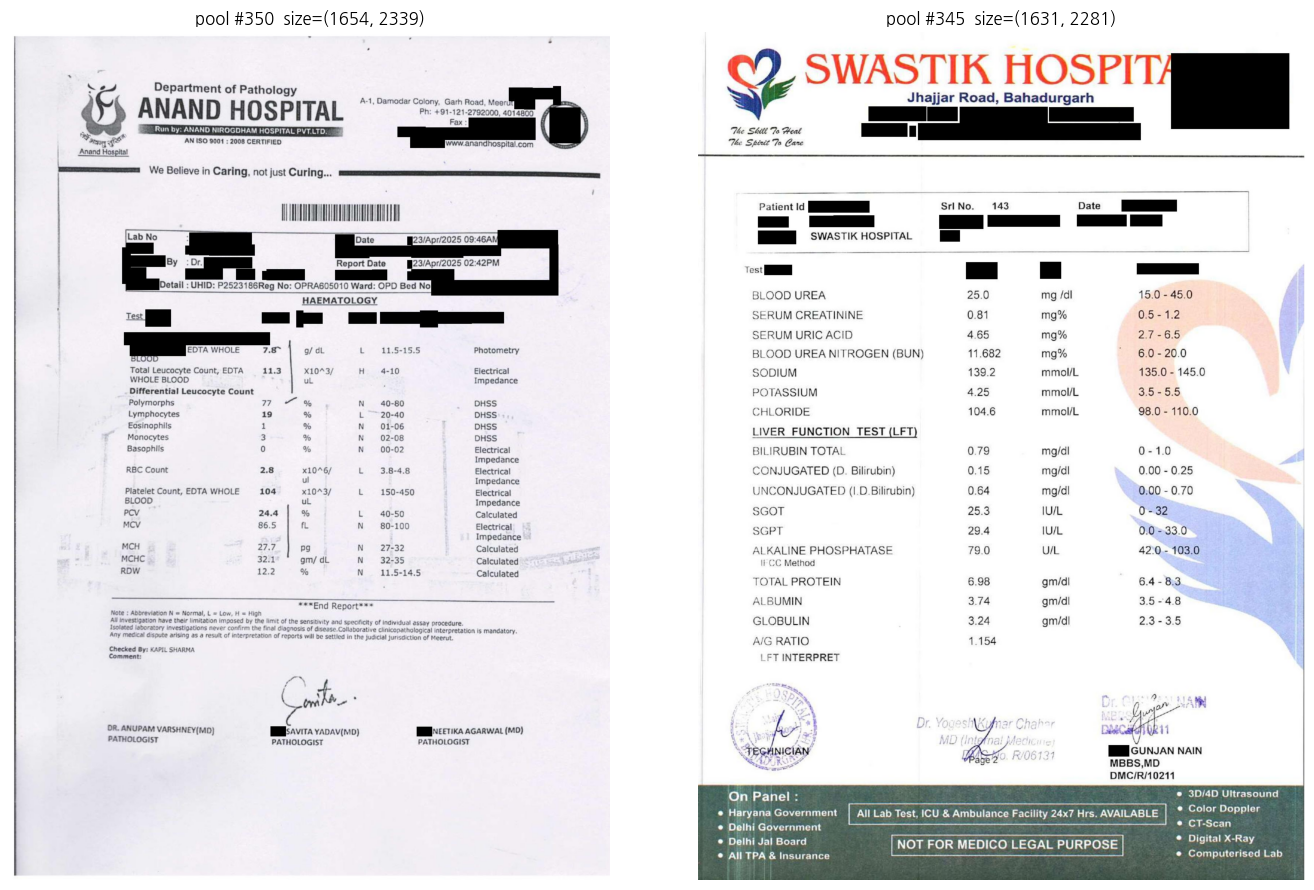

**Department of Pathology** ANAND HOSPITAL Run by: ANAND NIROGDHAM HOSPITAL PVT.LTD. A-1, Damodar Colony, Garh Road, Meerut Ph: +91-121-2792000, 4014800 Fax: [Redacted] www.anandhospital.com  We Believe in Caring, not just Curing...  ---  **HAEMATOLOGY**  **Lab No:** [Redacted]   **Date:** 23/Apr/2025 09:46AM   **By:** Dr. [Redacted]   **Report Date:** 23/Apr/2025 02:42PM   **Detail:** UHID: P2523186 Reg No: OPRA605010 Ward: OPD Bed No: [Redacted]  | Test | Value | Unit | Result | Reference Range | Method | |------|-------|------|--------|-----------------|--------| | EDTA WHOLE BLOOD | 7.8 | g/dL | L | 11.5-15.5 | Photometry | | Total Leucocyte Count, EDTA WHOLE BLOOD | 11.3 | X10^3/uL | H | 4-10 | Electrical Impedance | | **Differential Leucocyte Count** | | | | | DHSS | | Polymorphs | 7


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 9))
for ax, i in zip(axes, eval_idx[:2]):
    ax.imshow(pool[i]["image"]); ax.axis("off")
    ax.set_title(f"pool #{i}  size={pool[i]['image'].size}")
plt.tight_layout(); plt.show()
print(pool[eval_idx[0]]["text"][:800])

## 3. 모델 로딩 & OCR 함수 (박스 + 토큰 신뢰도)

In [7]:
processor = AutoProcessor.from_pretrained(MODEL_ID)
model = Florence2ForConditionalGeneration.from_pretrained(MODEL_ID, dtype=dtype).to(device).eval()
TASK = "<OCR_WITH_REGION>"


### OCR 파이프라인
- `deskew`: 스캔된 보고서가 기울어 있으면 같은 행의 검사명과 값이 다른 행으로 묶인다 → 수평 투영(projection) 분산이 가장 큰 각도를 찾아 보정
- `group_rows`: y 중심이 비슷한 박스를 한 행으로 묶기 (`row_tol` × 글자 높이)
- `merge_wrapped`: 검사명만 있는 행 + 바로 아래 값으로 시작하는 행 → 한 행으로 병합
- **안전장치**: 행마다 `needs_review`와 그 이유를 기록
  - `low_conf`: 신뢰도 < CONF_THR
  - `printed_mismatch`: 보고서에 **인쇄된 H/L·↑↓ 표시**와 계산한 플래그가 다름 → 값을 잘못 읽었을 가능성
  - `critical`: 참고범위의 절반 미만 또는 2배 초과 → **실제 위험 수치이거나 자릿수 오류** (둘 다 사람 확인 필요)
  - `no_flag` *(2차)*: 값은 읽었지만 참고범위를 못 읽어 H/L/N **판정 불가**
  - `range_suspect` *(2차)*: 읽은 참고범위가 그 검사의 **일반적인 참고범위**와 3배 이상 동떨어짐 → 다른 행의 범위가 붙었을 가능성 (예: Sodium에 크레아티닌 범위 0.4–1.2)


In [8]:
LOC = re.compile(r'^<loc_\d+>$')
TASK = "<OCR_WITH_REGION>"

def segment_confidences(tokens, probs):
    """Florence-2 OCR 출력: [텍스트 토큰들][loc 토큰 8개] 반복 → 텍스트 구간별 (평균, 최소) 신뢰도"""
    segs, cur = [], []
    for t, p in zip(tokens, probs):
        if t in ('</s>', '<s>', '<pad>'): continue
        if LOC.match(t):
            if cur: segs.append(cur); cur = []
        else:
            cur.append(p)
    return [(float(np.mean(s)), float(np.min(s))) for s in segs]

def quad_to_box(q):
    xs, ys = q[0::2], q[1::2]
    return [min(xs), min(ys), max(xs), max(ys)]

def iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    if inter == 0: return 0.0
    return inter / ((a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter)

def contain(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    return ix * iy / max(1e-6, (a[2]-a[0])*(a[3]-a[1]))

def dedupe(items):
    """타일 겹침 영역에서 중복 인식된 박스 제거 (신뢰도 높은 쪽 유지)"""
    items = sorted(items, key=lambda d: -d['conf'])
    keep = []
    for d in items:
        if any(iou(d['box'], k['box']) > 0.5 or contain(d['box'], k['box']) > 0.8 for k in keep): continue
        keep.append(d)
    return keep

def make_tiles(W, H, overlap=0.1, max_tiles=12):
    cols = 2 if W > 1000 else 1
    tw = W / cols
    rows = max(1, math.ceil(H / tw))
    while rows * cols > max_tiles: rows -= 1
    th = H / rows
    tiles = []
    for r in range(rows):
        for c in range(cols):
            x0 = max(0, c*tw - overlap*tw); x1 = min(W, (c+1)*tw + overlap*tw)
            y0 = max(0, r*th - overlap*th); y1 = min(H, (r+1)*th + overlap*th)
            tiles.append(tuple(int(v) for v in (x0, y0, x1, y1)))
    return tiles

def deskew(img, max_angle=3.0, step=0.25):
    """수평 투영 분산이 최대가 되는 각도 탐색 → (보정된 이미지, 각도)"""
    g = img.convert("L"); w, h = g.size; s = 1000 / max(w, h)
    small = (np.array(g.resize((max(1, int(w*s)), max(1, int(h*s))))) < 128).astype(np.uint8) * 255
    small = Image.fromarray(small)
    best, best_a = -1, 0.0
    for a in np.arange(-max_angle, max_angle + 1e-6, step):
        prof = (np.array(small.rotate(a, fillcolor=0)) > 0).sum(1)
        v = float(np.var(prof))
        if v > best: best, best_a = v, float(a)
    if abs(best_a) < step: return img, 0.0
    return img.rotate(best_a, expand=True, fillcolor="white"), best_a

def group_rows(items, tol_ratio=0.5):
    """y 중심이 비슷한 박스끼리 한 행으로 묶고, 행 안에서는 x 순서로 정렬"""
    if not items: return []
    tol = tol_ratio * float(np.median([d['box'][3]-d['box'][1] for d in items]))
    items = sorted(items, key=lambda d: (d['box'][1]+d['box'][3])/2)
    rows, cur, cy = [], [items[0]], (items[0]['box'][1]+items[0]['box'][3])/2
    for d in items[1:]:
        c = (d['box'][1]+d['box'][3])/2
        if abs(c - cy) <= tol:
            cur.append(d); cy = np.mean([(x['box'][1]+x['box'][3])/2 for x in cur])
        else:
            rows.append(sorted(cur, key=lambda x: x['box'][0])); cur, cy = [d], c
    rows.append(sorted(cur, key=lambda x: x['box'][0]))
    return rows

def merge_wrapped(rows):
    """숫자 없는 행(검사명만) + 바로 아래 '값으로 시작하는 행' → 한 행으로 병합"""
    out, i = [], 0
    while i < len(rows):
        t = " ".join(d["text"] for d in rows[i])
        if i + 1 < len(rows) and not re.search(r"\d", t) and re.match(r"^[<>]?\d", rows[i+1][0]["text"].strip()):
            out.append(rows[i] + rows[i+1]); i += 2
        else:
            out.append(rows[i]); i += 1
    return out

@torch.no_grad()
def ocr_image(img):
    """이미지 1장 → [{box, text, conf, conf_min}] (좌표는 입력 이미지 기준)"""
    inputs = processor(text=TASK, images=img, return_tensors="pt").to(device, dtype)
    out = model.generate(**inputs, max_new_tokens=1024, num_beams=1, do_sample=False,
                         return_dict_in_generate=True, output_scores=True)
    T = len(out.scores)
    gen_ids = out.sequences[0, -T:]
    logp = model.compute_transition_scores(out.sequences, out.scores, normalize_logits=True)[0]
    probs = logp.float().exp().cpu().numpy()
    toks = processor.tokenizer.convert_ids_to_tokens(gen_ids.tolist())
    confs = segment_confidences(toks, probs)
    text = processor.batch_decode(out.sequences, skip_special_tokens=False)[0]
    res = processor.post_process_generation(text, task=TASK, image_size=img.size)[TASK]
    labels = [l.replace("</s>", "").replace("<s>", "").strip() for l in res["labels"]]
    aligned = len(confs) == len(labels)
    items = []
    for k, (q, lab) in enumerate(zip(res["quad_boxes"], labels)):
        if not lab: continue
        c, cmin = confs[k] if aligned else (np.nan, np.nan)
        items.append(dict(box=quad_to_box(q), text=lab, conf=c, conf_min=cmin))
    return items

def ocr_page(img, cfg):
    if not cfg["tiled"]:
        items = ocr_image(img)
    else:
        items = []
        for (x0, y0, x1, y1) in make_tiles(*img.size, overlap=cfg["overlap"], max_tiles=cfg["max_tiles"]):
            for d in ocr_image(img.crop((x0, y0, x1, y1))):
                b = d["box"]; d["box"] = [b[0]+x0, b[1]+y0, b[2]+x0, b[3]+y0]
                items.append(d)
    for d in items:                               # 정렬 실패로 신뢰도가 없으면 0.5(=검토 경계)로 둠
        if np.isnan(d["conf"]): d["conf"] = 0.5
        if np.isnan(d["conf_min"]): d["conf_min"] = d["conf"]
    return dedupe(items) if cfg["tiled"] else items

OCR_CACHE = {}
def get_ocr(i, cfg):
    """(보정된 이미지, OCR 박스, 보정 각도) — 같은 OCR 설정이면 캐시 재사용"""
    key = (i, cfg["tiled"], cfg["deskew"], cfg["overlap"], cfg["max_tiles"])
    if key not in OCR_CACHE:
        img, ang = pool[i]["image"].convert("RGB"), 0.0
        if cfg["deskew"]: img, ang = deskew(img)
        OCR_CACHE[key] = (img, ocr_page(img, cfg), ang)
    return OCR_CACHE[key]

PRINTED = re.compile(r"(?<![A-Za-z/])[\(\[]?(HIGH|LOW|High|Low|H|L)[\)\]]?(?![A-Za-z/])")
ARROW = re.compile(r"[↑↓▲▼]")
def printed_flag(row_text):
    """보고서에 인쇄된 표시: 화살표는 행 어디서나, H/L 글자는 값 뒤에서만 찾음 (없으면 None)"""
    a = ARROW.search(row_text)
    if a: return "H" if a.group(0) in "↑▲" else "L"
    m = re.search(r"\d", row_text)
    if not m: return None
    p = PRINTED.search(row_text[m.start():])
    if not p: return None
    return "H" if p.group(1) in ("H", "HIGH", "High") else "L"

# 주요 검사의 일반적인 성인 참고범위 (단위가 다른 경우 여러 개) — 범위가 '그럴듯한지'만 보는 용도
TYPICAL = [
    (("bloodureanitrogen", "bun"),                                  [(7, 20)]),
    (("sodium", "serumsodium", "na"),                               [(135, 145)]),
    (("potassium", "serumpotassium", "k"),                          [(3.5, 5.1)]),
    (("chloride", "serumchloride", "cl"),                           [(98, 107)]),
    (("creatinine", "serumcreatinine"),                             [(0.6, 1.3), (53, 115)]),
    (("urea", "bloodurea", "serumurea"),                            [(15, 45), (2.5, 7.1)]),
    (("uricacid", "serumuricacid"),                                 [(3.5, 7.2), (200, 430)]),
    (("calcium", "serumcalcium"),                                   [(8.5, 10.5), (2.1, 2.6)]),
    (("haemoglobin", "hemoglobin", "hb", "hbhaemoglobin", "hbhemoglobin"), [(12, 17), (120, 170)]),
    (("plateletcount", "platelets", "plt"),                         [(150, 450), (1.5, 4.5), (150000, 450000)]),
    (("totalleucocytecount", "totalleukocytecount", "tlc", "totalwbccount", "wbccount", "wbc"),
                                                                    [(4, 11), (4000, 11000)]),
    (("rbccount", "totalrbc", "totalredbloodcount", "redbloodcellcount", "rbc"), [(4, 6)]),
    (("bilirubintotal", "totalbilirubin", "serumbilirubintotal"),   [(0.2, 1.2), (3, 21)]),
    (("albumin", "serumalbumin"),                                   [(3.5, 5.2), (35, 52)]),
]
def typical_ranges(key):
    for aliases, rngs in TYPICAL:
        for a in aliases:
            if key == a or (len(a) >= 4 and key.startswith(a)):
                return rngs
    return None

def range_suspect(r):
    """읽은 참고범위의 중앙값이 그 검사의 일반 참고범위(어느 단위로든)와 3배 이상 다르면 True"""
    rngs = typical_ranges(r["key"])
    if not rngs or r["lo"] is None or r["hi"] is None: return False
    mid = (r["lo"] + r["hi"]) / 2
    return not any(lo / 3 <= mid <= hi * 3 for lo, hi in rngs)

def extract_tests(items, cfg):
    """OCR 박스 → 행 → 검사결과 + 근거 박스 + 신뢰도 + 사람 검토 여부"""
    sex = detect_sex(" ".join(d["text"] for d in items))
    rows = group_rows(items, cfg["row_tol"])
    if cfg["merge_rows"]: rows = merge_wrapped(rows)
    tests = []
    for row in rows:
        row_text = " ".join(d["text"] for d in row)
        r = parse_row(row_text, sex)
        if not (r and r["key"]): continue
        r["boxes"] = [d["box"] for d in row]
        r["conf"] = float(min(d["conf_min"] for d in row))
        r["printed"] = printed_flag(row_text)
        reasons = []
        if r["conf"] < CONF_THR: reasons.append("low_conf")
        if r["printed"] and r["flag"] in ("H", "L", "N") and r["printed"] != r["flag"]: reasons.append("printed_mismatch")
        if (r["lo"] and r["value"] < 0.5 * r["lo"]) or (r["hi"] and r["value"] > 2 * r["hi"]): reasons.append("critical")
        if r["flag"] is None: reasons.append("no_flag")
        if range_suspect(r): reasons.append("range_suspect")
        r["review"] = reasons
        tests.append(r)
    return tests


In [9]:
# 한 장으로 먼저 확인 (최종 설정)
t = time.time(); img0, items0, ang0 = get_ocr(eval_idx[0], MODES[FINAL])
print(f"{len(items0)}개 텍스트 박스, {time.time()-t:.1f}s, 기울기 보정 {ang0:+.2f}°")
tests0 = extract_tests(items0, MODES[FINAL])
pd.DataFrame([{k: v for k, v in r.items() if k not in ("boxes", "key")} for r in tests0])


133개 텍스트 박스, 25.2s, 기울기 보정 +0.50°


,name,value,unit,lo,hi,flag,conf,printed,review
0,"ANAND HOSPITAL Ph: +91-121-279200,",4014800.0,,NaN,NaN,None,0.206176,None,"[low_conf, no_flag]"
1,An ISO,9001.0,,NaN,NaN,None,0.537880,None,[no_flag]
2,Lab No Date,23.0,/Apr/2025,NaN,NaN,None,0.754292,None,[no_flag]
3,By : Dr. Report Date,23.0,/Apr/2025,NaN,NaN,None,0.386681,None,"[low_conf, no_flag]"
4,Detail: UHID: P2523186Reg No: OPRA6050010 Wardi,36.0,Reg,NaN,NaN,None,0.142910,None,"[low_conf, no_flag]"
5,EDTA WHOLE,7.8,g/dl,11.5,15.5,L,0.584950,L,[]
6,"Total Leucocyte Count, EDTA",11.3,X10/3/,4.0,10.0,H,0.557213,H,[]
7,Polymorphs,77.0,%,40.0,80.0,N,0.407260,None,[low_conf]
8,Lymphocytes,19.0,%,20.0,40.0,L,0.327519,L,[low_conf]
9,Eosinophils,1.0,%,1.0,6.0,N,0.319188,None,[low_conf]


## 4. 평가 — 정답 검사결과와 매칭
- **평가 대상**: 정답에서 **참고범위가 있는 행만** (날짜·접수번호·연락처 같은 비검사 행 제외)
- **검사 검출률**: 정답 검사 중 OCR이 찾은 비율 (검사명 유사도 ≥ 0.8)
  - *2차*: 다른 검사로 취급하는 경우 — *un-/non-* 접두어만 다름, **혈구 종류가 다름**(RBC↔WBC, 호중구↔호산구), **% ↔ 절대수치**, 5글자 이하 약어가 정확히 일치하지 않음(MCH↔MCHC)
  - *2차*: 한쪽 이름이 다른 쪽의 앞부분이면 같은 검사로 인정 (EDTA WHOLE ⊂ EDTA WHOLE BLOOD)
- **판정 불가**: 검사는 찾았지만 참고범위를 못 읽어 H/L/N을 정할 수 없음 (1차 혼동행렬의 'missed'에 섞여 있던 부분)
- **값 정확도**: 찾은 검사 중 결과값이 정확히 같은 비율
- **이상수치 민감도**: 정답 H/L을 OCR도 같은 플래그로 잡은 비율 → *놓치면 위험한 오류*
- **오경보율**: 정답 N인데 OCR이 H/L로 표시한 비율
- **사람 검토 비율 / 위험 오류 포착률**: 안전장치가 넘긴 비율, 그리고 *위험 오류(H/L을 놓치거나 뒤집음)* 중 검토 대상에 포함된 비율

> ⚠️ 검출 자체를 못 한 행(missed)은 안전장치도 볼 수 없다 → 검출률이 여전히 중요한 이유


In [10]:
def risky_pair(a, b):
    """'conjugated' vs 'unconjugated'처럼 접두어만 다르고 의미는 반대인 검사 쌍"""
    for p in ("un", "non"):
        for x, y in ((a, b), (b, a)):
            if x.startswith(p) and not y.startswith(p) and difflib.SequenceMatcher(None, x[len(p):], y).ratio() >= 0.9:
                return True
    return False

CELLS = {"neutrophil": "neu", "lymphocyte": "lym", "monocyte": "mon", "eosinophil": "eos", "basophil": "bas",
         "rbc": "rbc", "redblood": "rbc", "erythro": "rbc", "wbc": "wbc", "whiteblood": "wbc", "leuco": "wbc",
         "leuko": "wbc", "tlc": "wbc", "platelet": "plt"}
def cell_types(key):
    return {v for k, v in CELLS.items() if k in key}

def unit_kind(u):
    if not u: return None
    return "pct" if "%" in u else "abs"

def match_score(g, o):
    a, b = g["key"], o["key"]
    if not a or not b or risky_pair(a, b): return 0
    if min(len(a), len(b)) <= 5 and a != b: return 0                      # MCH ↔ MCHC, RBC ↔ RDW 등
    ca, cb = cell_types(a), cell_types(b)
    if ca and cb and ca != cb: return 0                                   # RBC ↔ WBC, 호중구 ↔ 호산구
    ua, ub = unit_kind(g.get("unit")), unit_kind(o.get("unit"))
    if ua and ub and ua != ub: return 0                                   # % ↔ 절대수치
    s = difflib.SequenceMatcher(None, a, b).ratio()
    short, long_ = sorted((a, b), key=len)
    if len(short) >= 6 and long_.startswith(short): s = max(s, 0.95)     # EDTA WHOLE ⊂ EDTA WHOLE BLOOD
    return s

def gt_tests(i):
    return [g for g in parse_text(pool[i]["text"]) if g["lo"] is not None or g["hi"] is not None]

def match(gts, ocr_tests):
    recs, seen = [], set()
    for g in gts:
        sk = (g["key"], unit_kind(g.get("unit")))
        if sk in seen: continue
        seen.add(sk)
        best, score = None, 0
        for o in ocr_tests:
            s = match_score(g, o)
            if s > score: best, score = o, s
        ok = best is not None and score >= 0.8
        recs.append(dict(test=g["name"], key=g["key"], gt_val=g["value"], gt_flag=g["flag"], matched=ok,
                         ocr_val=best["value"] if ok else None, ocr_flag=best["flag"] if ok else None,
                         conf=best["conf"] if ok else np.nan, printed=best["printed"] if ok else None,
                         review=",".join(best["review"]) if ok else "", needs_review=bool(ok and best["review"]),
                         val_ok=ok and abs(best["value"] - g["value"]) < 1e-6,
                         _boxes=best["boxes"] if ok else None))
    return recs

def run(name):
    cfg, rows, t0 = MODES[name], [], time.time()
    for n, i in enumerate(eval_idx):
        _, items, _ = get_ocr(i, cfg)
        for r in match(gt_tests(i), extract_tests(items, cfg)):
            r["doc"] = i; rows.append(r)
        print(f"\r{name}: {n+1}/{len(eval_idx)}", end="")
    sec = time.time() - t0
    print(f"  ({sec:.0f}s)")
    return pd.DataFrame(rows), sec

def summarize(df):
    m = df[df.matched]
    abn = df[df.gt_flag.isin(["H", "L"])]
    nor = m[m.gt_flag == "N"]
    danger = m[m.gt_flag.isin(["H", "L"]) & (m.ocr_flag != m.gt_flag)]
    flip = danger[danger.ocr_flag.notna()]
    val_err = m[~m.val_ok]
    return {
        "GT 검사 수": len(df),
        "검사 검출률": df.matched.mean(),
        "값 정확도(검출된 것 중)": m.val_ok.mean(),
        "플래그 일치율": (df.ocr_flag == df.gt_flag).mean(),
        "이상수치 민감도": (abn.ocr_flag == abn.gt_flag).mean() if len(abn) else np.nan,
        "오경보율": nor.ocr_flag.isin(["H", "L"]).mean() if len(nor) else np.nan,
        "사람 검토 비율": m.needs_review.mean(),
        "판정 불가 비율(검출된 것 중)": m.ocr_flag.isna().mean(),
        "위험 오류 수(합계)": len(danger),
        "  └ 플래그 뒤집힘(H↔L, 이상→N)": len(flip),
        "  └ 이상수치인데 판정 불가": len(danger) - len(flip),
        "위험 오류 포착률": danger.needs_review.mean() if len(danger) else np.nan,
        "값 오류 포착률": val_err.needs_review.mean() if len(val_err) else np.nan,
    }


In [11]:
results, times = {}, {}
for name in MODES:
    results[name], times[name] = run(name)

summary = pd.DataFrame({k: summarize(v) for k, v in results.items()})
summary.loc["소요 시간(초)"] = [round(times[k]) for k in MODES]   # ③은 ②의 OCR을 재사용하므로 짧게 나옴
summary.round(3)


① 전체 이미지: 20/20  (129s)
② 타일 분할: 20/20  (236s)
③ +행 묶기 개선: 20/20  (0s)
④ +기울기 보정·겹침: 20/20  (275s)


,① 전체 이미지,② 타일 분할,③ +행 묶기 개선,④ +기울기 보정·겹침
GT 검사 수,219.000,219.000,219.000,219.000
검사 검출률,0.470,0.826,0.822,0.904
값 정확도(검출된 것 중),0.612,0.945,0.939,0.904
플래그 일치율,0.178,0.607,0.667,0.749
이상수치 민감도,0.162,0.595,0.662,0.770
오경보율,0.091,0.009,0.017,0.016
사람 검토 비율,0.990,0.718,0.683,0.591
판정 불가 비율(검출된 것 중),0.534,0.249,0.156,0.116
위험 오류 수(합계),25.000,22.000,12.000,12.000
"└ 플래그 뒤집힘(H↔L, 이상→N)",3.000,2.000,4.000,9.000


In [13]:
# 1차 vs 2차 (④ 최종 설정 기준)
cmp = pd.DataFrame({"1차 (④)": pd.Series(PREV), "2차 (④)": summary[FINAL]})
cmp["변화"] = cmp["2차 (④)"] - cmp["1차 (④)"]
cmp.round(3)


,1차 (④),2차 (④),변화
└ 이상수치인데 판정 불가,NaN,3.000,NaN
"└ 플래그 뒤집힘(H↔L, 이상→N)",NaN,9.000,NaN
GT 검사 수,217.000,219.000,2.000
값 오류 포착률,0.765,0.789,0.024
값 정확도(검출된 것 중),0.909,0.904,-0.005
검사 검출률,0.862,0.904,0.042
사람 검토 비율,0.567,0.591,0.024
소요 시간(초),NaN,275.000,NaN
오경보율,0.024,0.016,-0.008
위험 오류 수(합계),12.000,12.000,0.000


In [12]:
!apt-get -qq install -y fonts-nanum > /dev/null
import matplotlib.font_manager as fm
fm.fontManager.addfont("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")
plt.rcParams["font.family"] = "NanumGothic"
plt.rcParams["axes.unicode_minus"] = False   # 한글 폰트에서 마이너스(−) 기호 깨짐 방지

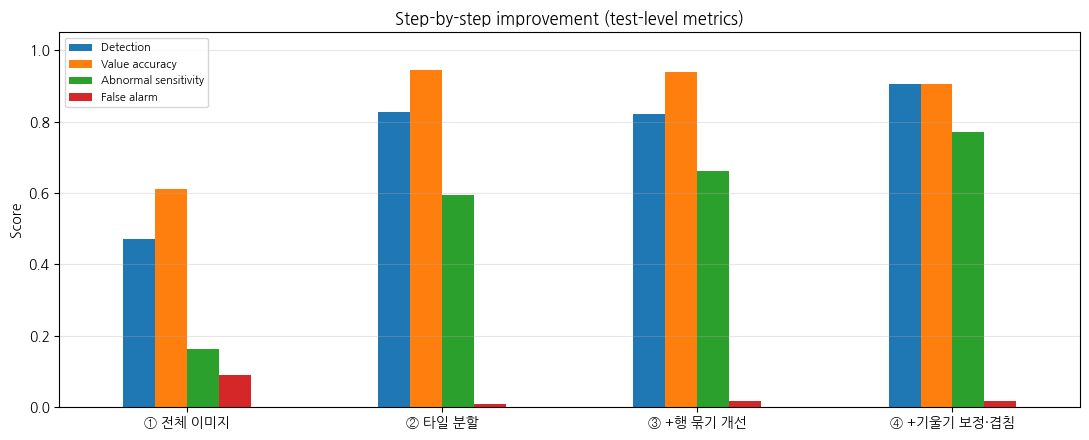

In [14]:
# 단계별 비교 그래프 (보고서 성능 그림)
keys = ["검사 검출률", "값 정확도(검출된 것 중)", "이상수치 민감도", "오경보율"]
ax = summary.loc[keys].astype(float).T.plot.bar(figsize=(11, 4.5), rot=0)
ax.set_ylim(0, 1.05); ax.set_ylabel("Score"); ax.grid(axis="y", alpha=0.3)
ax.set_title("Step-by-step improvement (test-level metrics)")
ax.legend(["Detection", "Value accuracy", "Abnormal sensitivity", "False alarm"], loc="upper left", fontsize=8)
plt.tight_layout(); plt.savefig("improvement_steps.png", dpi=150); plt.show()


## 5. 누락 원인 진단 — 왜 못 찾았나?
| 원인 | 의미 | 대응 |
|---|---|---|
| **인식 실패** (recognition) | OCR 결과 어디에도 검사명이 없음 | 해상도·모델 크기 |
| **행 묶기/파싱 실패** (grouping/parsing) | 글자는 읽었지만 검사명과 값이 다른 행으로 갈림 | 행 묶기 규칙 |


In [15]:
def diagnose(df, name):
    cfg = MODES[name]; out = Counter()
    for i in eval_idx:
        _, items, _ = get_ocr(i, cfg)
        all_text = norm_name(" ".join(d["text"] for d in items))
        for _, r in df[(df.doc == i) & ~df.matched].iterrows():
            out["행 묶기/파싱 실패" if r.key[:8] in all_text else "인식 실패"] += 1
    return out

diag = pd.DataFrame({k: diagnose(results[k], k) for k in ["② 타일 분할", FINAL]}).fillna(0).astype(int)
diag


,② 타일 분할,④ +기울기 보정·겹침
행 묶기/파싱 실패,32,15
인식 실패,6,6


In [16]:
def failed_rows(name=FINAL):
    cfg, df, out = MODES[name], results[name], []
    for i in eval_idx:
        _, items, _ = get_ocr(i, cfg)
        rows = group_rows(items, cfg["row_tol"])
        if cfg["merge_rows"]: rows = merge_wrapped(rows)
        all_text = norm_name(" ".join(d["text"] for d in items))
        for _, r in df[(df.doc == i) & ~df.matched].iterrows():
            hit = next((row for row in rows if r.key[:8] in norm_name(" ".join(d["text"] for d in row))), None)
            out.append(dict(doc=i,
                            cause="행 묶기/파싱 실패" if r.key[:8] in all_text else "인식 실패",
                            test=r.test, gt_val=r.gt_val, gt_flag=r.gt_flag,
                            ocr_row=" ".join(d["text"] for d in hit)[:120] if hit else "",
                            _boxes=[d["box"] for d in hit] if hit else None))
    return pd.DataFrame(out)

fail = failed_rows()
pd.set_option("display.max_colwidth", 120)
fail.drop(columns="_boxes").sort_values(["cause", "doc"])

,doc,cause,test,gt_val,gt_flag,ocr_row
14,268,인식 실패,EOSINOPHILS,2.00,N,EOSINOPHILS D % 1-5
15,268,인식 실패,BASOPHILS,0.00,N,
16,268,인식 실패,RDW,14.80,N,
2,345,인식 실패,UNCONJUGATED (I.D. Bilirubin),0.64,N,
19,476,인식 실패,Monocytes,2.00,N,
20,476,인식 실패,H.C.T,40.10,L,
12,41,행 묶기/파싱 실패,Urea,104.00,H,Urea 01:26PM Unit Bio Ref Interval
8,113,행 묶기/파싱 실패,Grant Medical Foundation Ruby Hall Clinic Wanowarie,59.00,N,Grant Medical Foundation QUALITY OF CINES
9,113,행 묶기/파싱 실패,Absolute Monocyte Count,0.84,N,Absolute Neutrophil Count : 8:15 x103cells/ul 2-7
10,113,행 묶기/파싱 실패,R.B.C Count,2.80,L,R.B.C Count : 2:8 million/ul 4.5-5.5


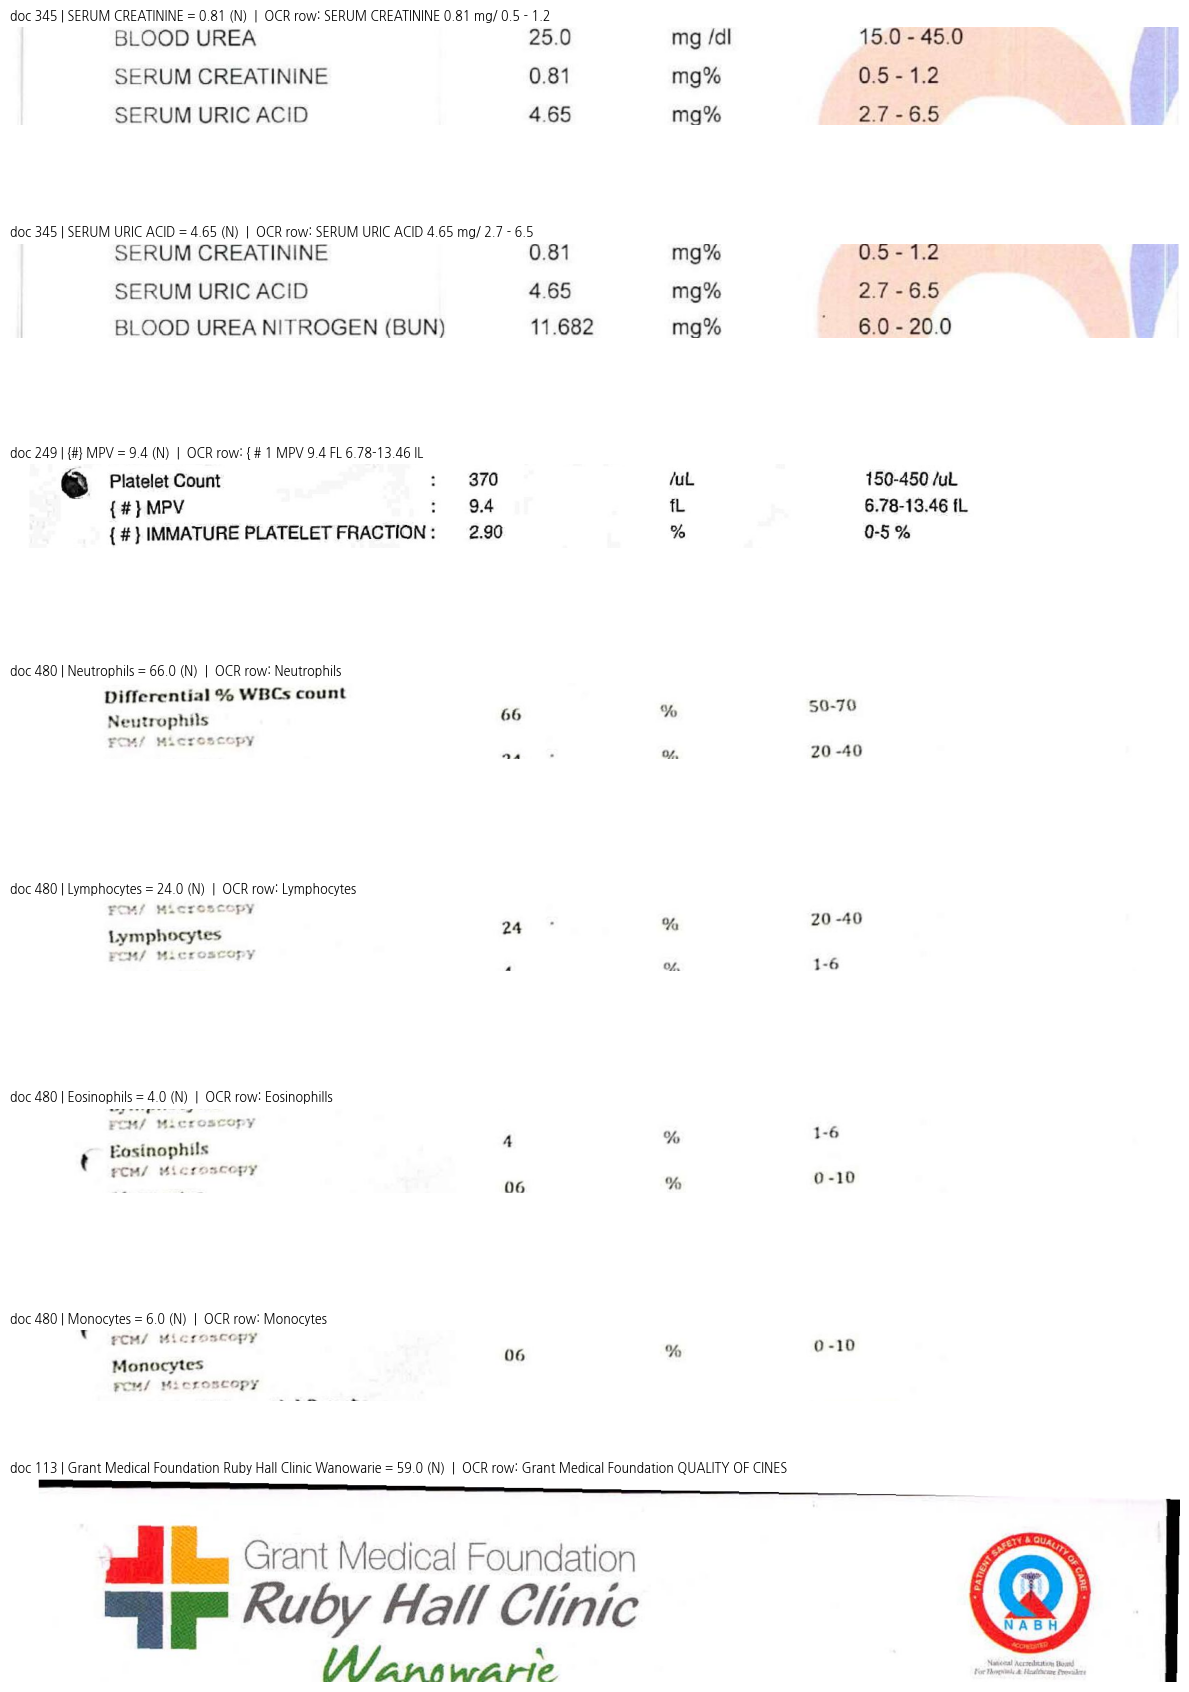

In [17]:
def show_fail_crops(fail, cause="행 묶기/파싱 실패", n=8):
    g = fail[(fail.cause == cause) & fail._boxes.notna()].head(n)
    if len(g) == 0: print("해당 사례 없음"); return
    fig, axes = plt.subplots(len(g), 1, figsize=(12, 2.2 * len(g)))
    axes = np.atleast_1d(axes)
    for ax, (_, r) in zip(axes, g.iterrows()):
        img, _, _ = get_ocr(int(r.doc), MODES[FINAL])
        ys = [b[1] for b in r._boxes] + [b[3] for b in r._boxes]
        h = max(ys) - min(ys)
        ax.imshow(img.crop((0, max(0, min(ys) - 1.5*h), img.size[0], max(ys) + 1.5*h))); ax.axis("off")
        ax.set_title(f"doc {r.doc} | {r.test} = {r.gt_val} ({r.gt_flag})  |  OCR row: {r.ocr_row[:70]}",
                     fontsize=9, loc="left")
    plt.tight_layout(); plt.savefig("missed_gallery.png", dpi=150); plt.show()

show_fail_crops(fail)

In [24]:
fail.drop(columns="_boxes").sort_values(["cause", "doc"]).to_csv(
    "missed_tests_2.csv", index=False, encoding="utf-8-sig")   # utf-8-sig: 엑셀에서 한글이 깨지지 않게
print(f"saved: missed_tests_2.csv ({len(fail)}행)")

from google.colab import files
files.download("missed_tests_2.csv")   # 내 컴퓨터로 바로 다운로드

saved: missed_tests_2.csv (21행)


In [25]:
# 이상수치 플래그 혼동행렬 (최종 설정)
# 'missed' = 검사 자체를 못 찾음 / 'no_flag' = 찾았지만 참고범위를 못 읽어 판정 불가
f = results[FINAL].copy()
f["ocr_flag"] = np.where(~f.matched, "missed", f.ocr_flag.fillna("no_flag"))
pd.crosstab(f.gt_flag, f.ocr_flag, rownames=["정답"], colnames=["OCR"])[
    [c for c in ["H", "L", "N", "no_flag", "missed"] if c in set(f.ocr_flag)]]


OCR,H,L,N,no_flag,missed
정답,,,,,
H,23,2,3,0,2
L,3,34,1,3,3
N,1,1,107,20,16


In [26]:
df = results[FINAL]

# 1) missed 칸 — 원인(cause)과 함께 보기
missed = fail.drop(columns="_boxes").copy()
print(missed.gt_flag.value_counts())          # H 4, L 10, N 36 과 일치해야 함
missed_abn = missed[missed.gt_flag.isin(["H", "L"])].sort_values(["gt_flag", "doc"])
missed_abn                                     # 임상적으로 가장 중요한: 놓친 이상수치 14건

gt_flag
N    16
L     3
H     2
Name: count, dtype: int64


,doc,cause,test,gt_val,gt_flag,ocr_row
12,41,행 묶기/파싱 실패,Urea,104.0,H,Urea 01:26PM Unit Bio Ref Interval
18,268,행 묶기/파싱 실패,MPV,10.2,H,MPV
10,113,행 묶기/파싱 실패,R.B.C Count,2.8,L,R.B.C Count : 2:8 million/ul 4.5-5.5
13,268,행 묶기/파싱 실패,HB (HAEMOGLOBIN),9.9,L,HB (HAEMOGLOBIN
20,476,인식 실패,H.C.T,40.1,L,


In [27]:
# 2) 검출은 됐지만 플래그가 틀린 행 (H→L, H→N, L→H, L→N, N→H, N→L)
wrong = df[df.matched & (df.ocr_flag != df.gt_flag)].drop(columns="_boxes")
wrong["type"] = np.where(wrong.ocr_flag.isna(), "판정 불가", "플래그 틀림")
wrong = wrong[["type", "doc", "test", "gt_val", "gt_flag", "ocr_val", "ocr_flag", "conf", "printed", "review"]]
wrong.sort_values(["type", "gt_flag", "ocr_flag"])

,type,doc,test,gt_val,gt_flag,ocr_val,ocr_flag,conf,printed,review
32,판정 불가,249,Haematocrit (PCV/HCT),27.200,L,27.200,None,0.569632,L,no_flag
140,판정 불가,406,GLOBULIN,1.700,L,1.700,None,0.525794,None,no_flag
204,판정 불가,476,Total R.B.C,4.420,L,4.420,None,0.528404,None,no_flag
18,판정 불가,345,SODIUM,139.200,N,139.200,None,0.249465,None,"low_conf,no_flag"
20,판정 불가,345,CHLORIDE,104.600,N,104.600,None,0.455383,None,"low_conf,no_flag"
21,판정 불가,345,BILIRUBIN TOTAL,0.790,N,0.790,None,0.516268,None,no_flag
34,판정 불가,249,Mean Corpuscular Hb (M.C.H.),28.500,N,33.500,None,0.101600,None,"low_conf,no_flag"
35,판정 불가,249,Mean Corpuscular Hb Conc (M.C.H.C.),33.500,N,33.500,None,0.101600,None,"low_conf,no_flag"
69,판정 불가,480,"Absolute Eosinophils Count, AEC",368.000,N,398000.000,None,0.262257,None,"low_conf,no_flag"
81,판정 불가,113,Absolute Basophil Count,0.050,N,0.050,None,0.245923,None,"low_conf,no_flag"


In [28]:
missed.sort_values(["gt_flag", "cause", "doc"]).to_csv("missed_by_flag_2.csv", index=False, encoding="utf-8-sig")
wrong.to_csv("wrong_flags_2.csv", index=False, encoding="utf-8-sig")
files.download("missed_by_flag_2.csv"); files.download("wrong_flags_2.csv")

## 6. XAI ① — 근거 지도 (Evidence map)
각 플래그가 **원본 이미지의 어느 위치에서 나왔는지** 박스로 표시한다.
🔴 H · 🔵 L · 🟢 N · **점선 = 사람 검토 대상** (옆에 이유 표시: conf / printed / critical)


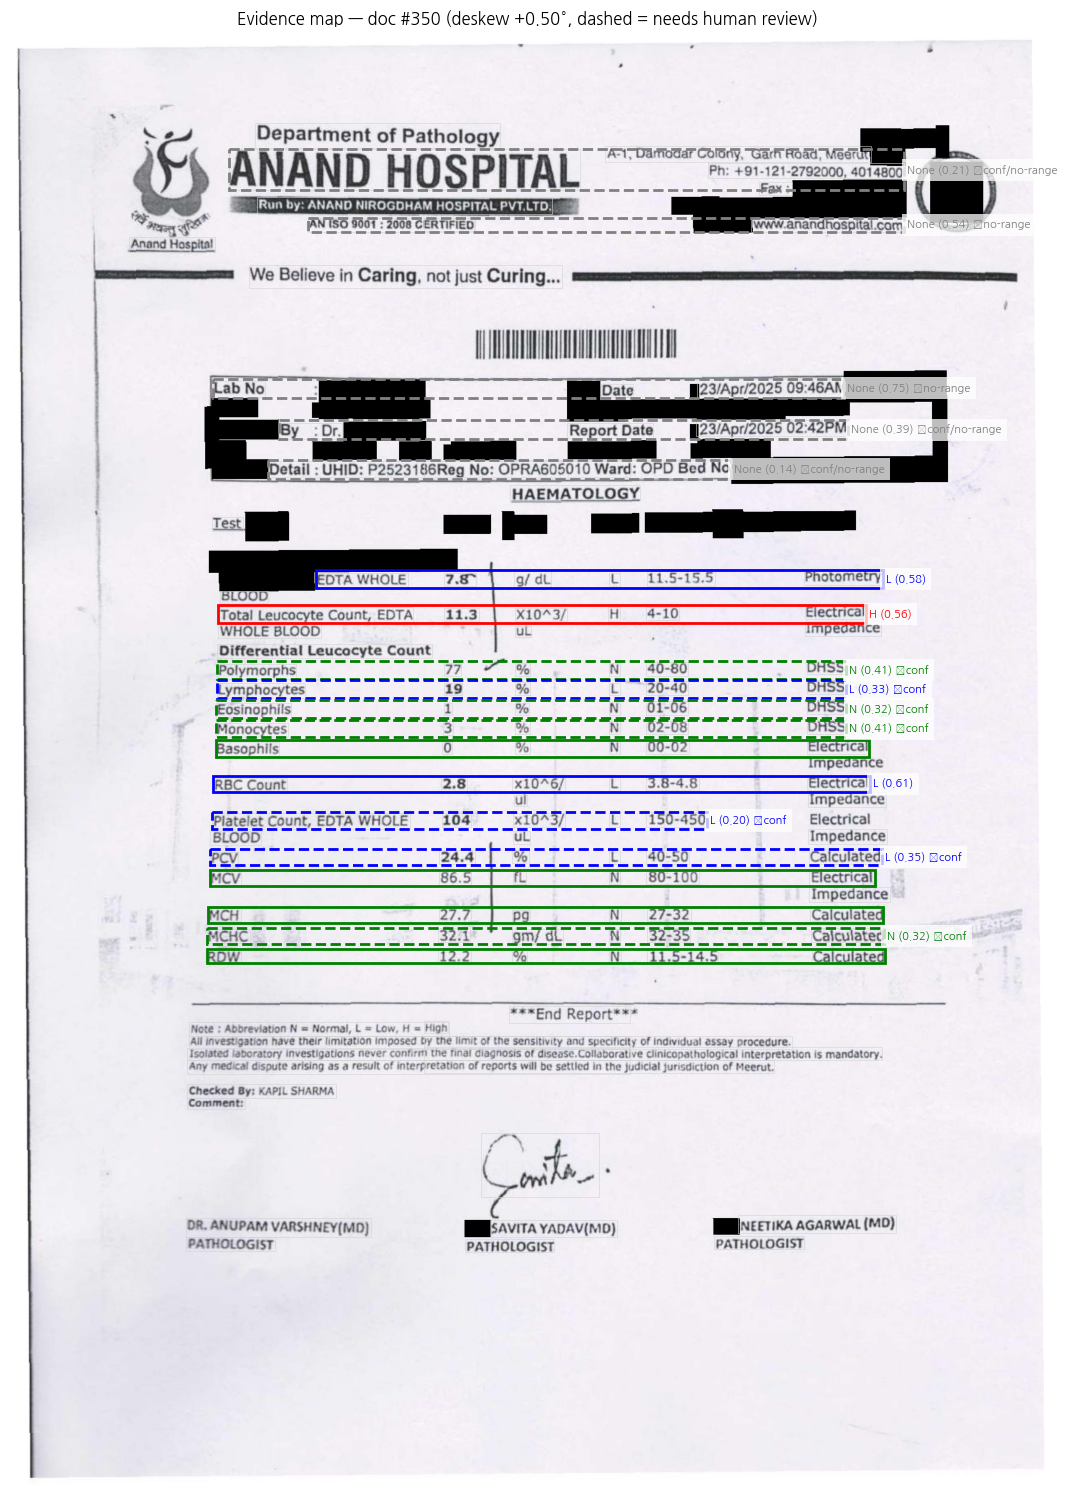

In [29]:
COL = {"H": "red", "L": "blue", "N": "green", None: "gray"}
SHORT = {"low_conf": "conf", "printed_mismatch": "printed", "critical": "critical",
         "no_flag": "no-range", "range_suspect": "range?"}
def evidence_map(i, name=FINAL):
    cfg = MODES[name]
    img, items, ang = get_ocr(i, cfg); tests = extract_tests(items, cfg)
    fig, ax = plt.subplots(figsize=(11, 11 * img.size[1] / img.size[0]))
    ax.imshow(img); ax.axis("off")
    for d in items:
        b = d["box"]; ax.add_patch(patches.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=False, lw=0.4, ec="lightgray"))
    for r in tests:
        xs = [b[0] for b in r["boxes"]] + [b[2] for b in r["boxes"]]
        ys = [b[1] for b in r["boxes"]] + [b[3] for b in r["boxes"]]
        ax.add_patch(patches.Rectangle((min(xs), min(ys)), max(xs)-min(xs), max(ys)-min(ys), fill=False,
                     lw=2, ec=COL[r["flag"]], ls="--" if r["review"] else "-"))
        if r["flag"] in ("H", "L") or r["review"]:
            label = f"{r['flag']} ({r['conf']:.2f})" + (" ⚑" + "/".join(SHORT[x] for x in r["review"]) if r["review"] else "")
            ax.text(max(xs) + 5, (min(ys)+max(ys))/2, label, color=COL[r["flag"]], fontsize=8, va="center",
                    weight="bold", bbox=dict(fc="white", alpha=0.75, lw=0))
    ax.set_title(f"Evidence map — doc #{i} (deskew {ang:+.2f}°, dashed = needs human review)")
    plt.tight_layout(); plt.savefig(f"evidence_map_{i}.png", dpi=150, bbox_inches="tight"); plt.show()

evidence_map(eval_idx[0])


## 7. XAI ② — 신뢰도는 오류를 예측하는가?
토큰 확률(행 안에서 가장 낮은 값)이 낮을수록 실제로 값이 틀리는지 확인한다.


             n  error_rate
conf_bin                  
(0.0, 0.3]  51       0.157
(0.3, 0.5]  54       0.093
(0.5, 0.7]  62       0.081
(0.7, 0.9]  27       0.037
(0.9, 1.0]   4       0.000

신뢰도 < 0.5: 105/198개 (53%), 오류율 0.124
신뢰도 ≥ 0.5: 93개, 오류율 0.065
→ 값 오류 중 '신뢰도 기준'만으로 걸러지는 비율: 0.68


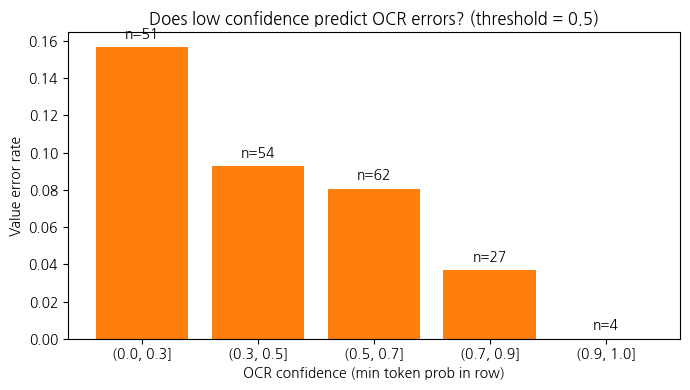

In [30]:
m = results[FINAL][results[FINAL].matched].copy()
m["conf_bin"] = pd.cut(m.conf, [0, 0.3, 0.5, 0.7, 0.9, 1.0])
tab = m.groupby("conf_bin", observed=True).agg(n=("val_ok", "size"), error_rate=("val_ok", lambda s: 1 - s.mean()))
print(tab.round(3))

low = m[m.conf < CONF_THR]
print(f"\n신뢰도 < {CONF_THR}: {len(low)}/{len(m)}개 ({len(low)/len(m):.0%}), 오류율 {1-low.val_ok.mean():.3f}")
print(f"신뢰도 ≥ {CONF_THR}: {len(m)-len(low)}개, 오류율 {1-m[m.conf >= CONF_THR].val_ok.mean():.3f}")
print(f"→ 값 오류 중 '신뢰도 기준'만으로 걸러지는 비율: {(~low.val_ok).sum() / max(1, (~m.val_ok).sum()):.2f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(tab.index.astype(str), tab.error_rate, color="tab:orange")
for k, (n, e) in enumerate(zip(tab.n, tab.error_rate)): ax.text(k, e + 0.005, f"n={n}", ha="center")
ax.set_xlabel("OCR confidence (min token prob in row)"); ax.set_ylabel("Value error rate")
ax.set_title(f"Does low confidence predict OCR errors? (threshold = {CONF_THR})")
plt.tight_layout(); plt.savefig("confidence_vs_error.png", dpi=150); plt.show()


## 8. XAI ③ — 안전장치는 위험한 오류를 잡는가?
각 검토 규칙이 몇 건을 넘겼고, 그중 실제 오류가 얼마나 포함됐는지 확인한다.


In [31]:
m = results[FINAL][results[FINAL].matched].copy()
m["value_error"] = ~m.val_ok
m["danger"] = m.gt_flag.isin(["H", "L"]) & (m.ocr_flag != m.gt_flag)
rule_rows = []
for rule in ["low_conf", "printed_mismatch", "critical", "no_flag", "range_suspect"]:
    hit = m[m.review.str.contains(rule)]
    rule_rows.append({"규칙": rule, "검토로 넘긴 수": len(hit), "그중 값 오류": int(hit.value_error.sum()),
                      "그중 위험 오류": int(hit.danger.sum())})
any_hit = m[m.needs_review]
rule_rows.append({"규칙": "하나라도 해당", "검토로 넘긴 수": len(any_hit), "그중 값 오류": int(any_hit.value_error.sum()),
                  "그중 위험 오류": int(any_hit.danger.sum())})
print(f"전체 검출 {len(m)}행 | 값 오류 {int(m.value_error.sum())}건 | 위험 오류 {int(m.danger.sum())}건")
pd.DataFrame(rule_rows)


전체 검출 198행 | 값 오류 19건 | 위험 오류 12건


,규칙,검토로 넘긴 수,그중 값 오류,그중 위험 오류
0,low_conf,105,13,6
1,printed_mismatch,0,0,0
2,critical,12,6,4
3,no_flag,23,4,3
4,range_suspect,3,1,2
5,하나라도 해당,117,15,9


## 9. XAI ④ — 오류 사례 수작업 검증
OCR 값 ≠ 정답 값인 행을 원본에서 잘라 보여준다. **누가 틀렸는지(OCR vs LLM 정답) 직접 판단**한다.
제목의 ⚑ 표시는 안전장치가 사람 검토로 넘긴 항목이다.


값 불일치 19건 중 상위 8건 표시


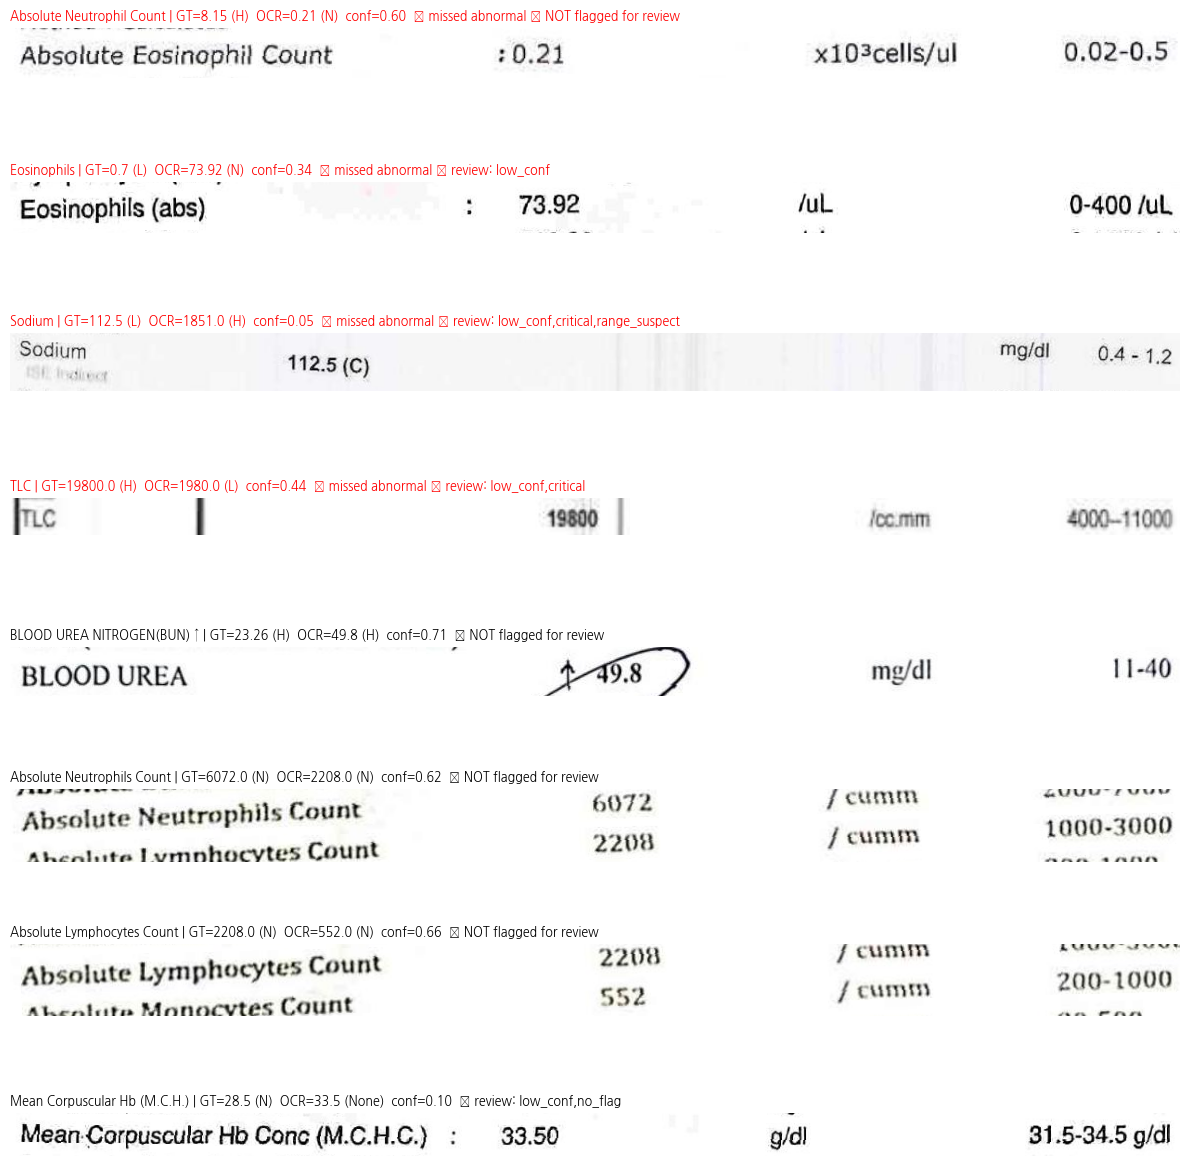

In [32]:
df = results[FINAL]
err = df[df.matched & ~df.val_ok].copy()
err["danger"] = err.gt_flag.isin(["H", "L"]) & (err.ocr_flag != err.gt_flag)
n_err = len(err)
err = err.sort_values(["danger", "needs_review"], ascending=[False, True]).head(8)
print(f"값 불일치 {n_err}건 중 상위 {len(err)}건 표시")

if len(err) == 0:
    print("값 불일치 사례 없음")
else:
    fig, axes = plt.subplots(len(err), 1, figsize=(12, 1.6 * len(err)))
    axes = np.atleast_1d(axes)
    for ax, (_, r) in zip(axes, err.iterrows()):
        img, _, _ = get_ocr(int(r.doc), MODES[FINAL])
        bx = r["_boxes"]
        xs = [b[0] for b in bx] + [b[2] for b in bx]; ys = [b[1] for b in bx] + [b[3] for b in bx]
        pad = 8
        ax.imshow(img.crop((max(0, min(xs)-pad), max(0, min(ys)-pad), max(xs)+pad, max(ys)+pad))); ax.axis("off")
        tag = ("⚠ missed abnormal " if r.danger else "") + (f"⚑ review: {r.review}" if r.needs_review else "✗ NOT flagged for review")
        ax.set_title(f"{r.test} | GT={r.gt_val} ({r.gt_flag})  OCR={r.ocr_val} ({r.ocr_flag})  conf={r.conf:.2f}  {tag}",
                     fontsize=9, loc="left", color="red" if r.danger else "black")
    plt.tight_layout(); plt.savefig("error_gallery.png", dpi=150); plt.show()


In [33]:
# 결과 저장 (보고서·GitHub용)
for k, v in results.items():
    v.drop(columns="_boxes").to_csv(f"results_{k[0]}.csv", index=False)
summary.round(3).to_csv("summary.csv")
print("saved: results_*.csv, summary.csv, improvement_steps.png, evidence_map_*.png, confidence_vs_error.png, error_gallery.png")


saved: results_*.csv, summary.csv, improvement_steps.png, evidence_map_*.png, confidence_vs_error.png, error_gallery.png


## 보고서 작성 가이드
| 보고서 항목 | 넣을 내용 |
|---|---|
| 그림 3 (추론 결과) | `evidence_map_*.png` — 점선·⚑ = 사람 검토 대상 |
| 그림 4 (학습 곡선 자리) | 파인튜닝이 없으므로 `improvement_steps.png`(단계별 개선) 또는 `confidence_vs_error.png`로 대체하고 이유를 한 줄로 적기 |
| 1차 vs 2차 | `cmp` 표 — 결과 분석 → 원인별 대응 → 재평가의 **개선 사이클**로 고찰에 서술 |
| 성능 수치 표 | '학습 전/후' 열 → **① 전체 이미지 / ④ 최종**으로 바꿔 `summary` 결과 기입 (②③은 본문에서 단계별 기여로 설명) |
| 고찰 | 누락 원인 진단 결과, 안전장치 규칙별 포착 결과, 오류 갤러리(OCR 오류 vs 평가 오류), 정답이 LLM 생성이라는 한계 |
| 비즈니스 | '틀릴 때 스스로 사람을 부르는 OCR' — 검사결과 디지털화·환자용 결과 해석 앱. 검토 비율 = 인건비, 위험 오류 포착률 = 안전성 |
